# Stack Overflow Question Quality Classifier

**CSE 575 – Statistical Machine Learning** · **P11: Learning from CQA data**

**Research question:** Can *textual and structural* features of a Stack Overflow question predict community-judged quality — without confusing quality with post type?

### What changed vs an earlier draft
Earlier models largely detected Stack Overflow **opinion-type** posts (`advice`, `best-practices`, `tooling-recommendation`) rather than writing quality. This notebook fixes that:

1. **Primary task** = normal Q&A questions only (opinion-types held out)
2. **Feature sets separated**: `text` | `struct` | `tags` | `text+struct` | `all`
3. **Headline metric = ROC-AUC** (all-high dummy F1 is a strong but uninformative baseline)
4. **Model selection by CV AUC only** (no test-set peeking)
5. **Chronological split** + **drop Score==0** sensitivity + **all-posts** secondary analysis (documents the tag confound)
6. Conservative **60-day** age filter; extracted **code text** used in TF-IDF; no hard-coded user paths

### How to run
Select the project `.venv` kernel and **Run All** (~8–15 minutes), or from the repo root:

```bash
MPLBACKEND=Agg python scripts/run_rigorous_pipeline.py
```


In [1]:
# 0. Setup
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / "data" / "stackoverflow_questions_2023plus.csv").exists():
    # allow running from scripts/
    if (ROOT.parent / "data" / "stackoverflow_questions_2023plus.csv").exists():
        ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "stackoverflow_questions_2023plus.csv"
FIG_DIR, RES_DIR = ROOT / "figures", ROOT / "results"
assert DATA_PATH.exists(), f"Missing dataset: {DATA_PATH}"
print("ROOT =", ROOT)
print("DATA =", DATA_PATH)
print("Note: CSV filename is historical; rows are from 2026-04 to 2026-10.")


ROOT = /Users/nithinreddy/Desktop/CSE-575_SML_Project
DATA = /Users/nithinreddy/Desktop/CSE-575_SML_Project/data/stackoverflow_questions_2023plus.csv
Note: CSV filename is historical; rows are from 2026-04 to 2026-10.


## 1. Run the rigorous pipeline

The full experiment lives in `scripts/run_rigorous_pipeline.py` (keeps the notebook readable and avoids duplicated logic). Re-running is safe; outputs overwrite `figures/` and `results/`.


In [2]:
# 1. Execute pipeline (skip if summary.json already fresh and SKIP_RERUN=True)
import subprocess, sys, os
SKIP_RERUN = os.environ.get("SKIP_RERUN", "0") == "1"
summary_path = RES_DIR / "summary.json"
if SKIP_RERUN and summary_path.exists():
    print("SKIP_RERUN=1 — loading existing results")
else:
    env = dict(os.environ)
    env["MPLBACKEND"] = "Agg"
    cmd = [sys.executable, str(ROOT / "scripts" / "run_rigorous_pipeline.py")]
    print("Running:", " ".join(cmd))
    subprocess.check_call(cmd, cwd=str(ROOT), env=env)
print("Done.")


SKIP_RERUN=1 — loading existing results
Done.


## 2. Data reality check: opinion-type confound & temporal drift


**Snapshot date:** 2026-10-27  ·  **Age filter:** ≥ 60 days  
**After filter:** 8077 questions  
**Normal Q&A:** 5616 (high-quality rate 50.5%)  
**Opinion-type:** 2461 (high-quality rate 4.5%)  
`FavoriteCount` is always 0 in this API export (not usable).


,is_opinion,n,high_rate,mean_score
0,Normal Q&A,5616,0.505164,0.830662
1,Opinion-type,2461,0.045104,-0.185697


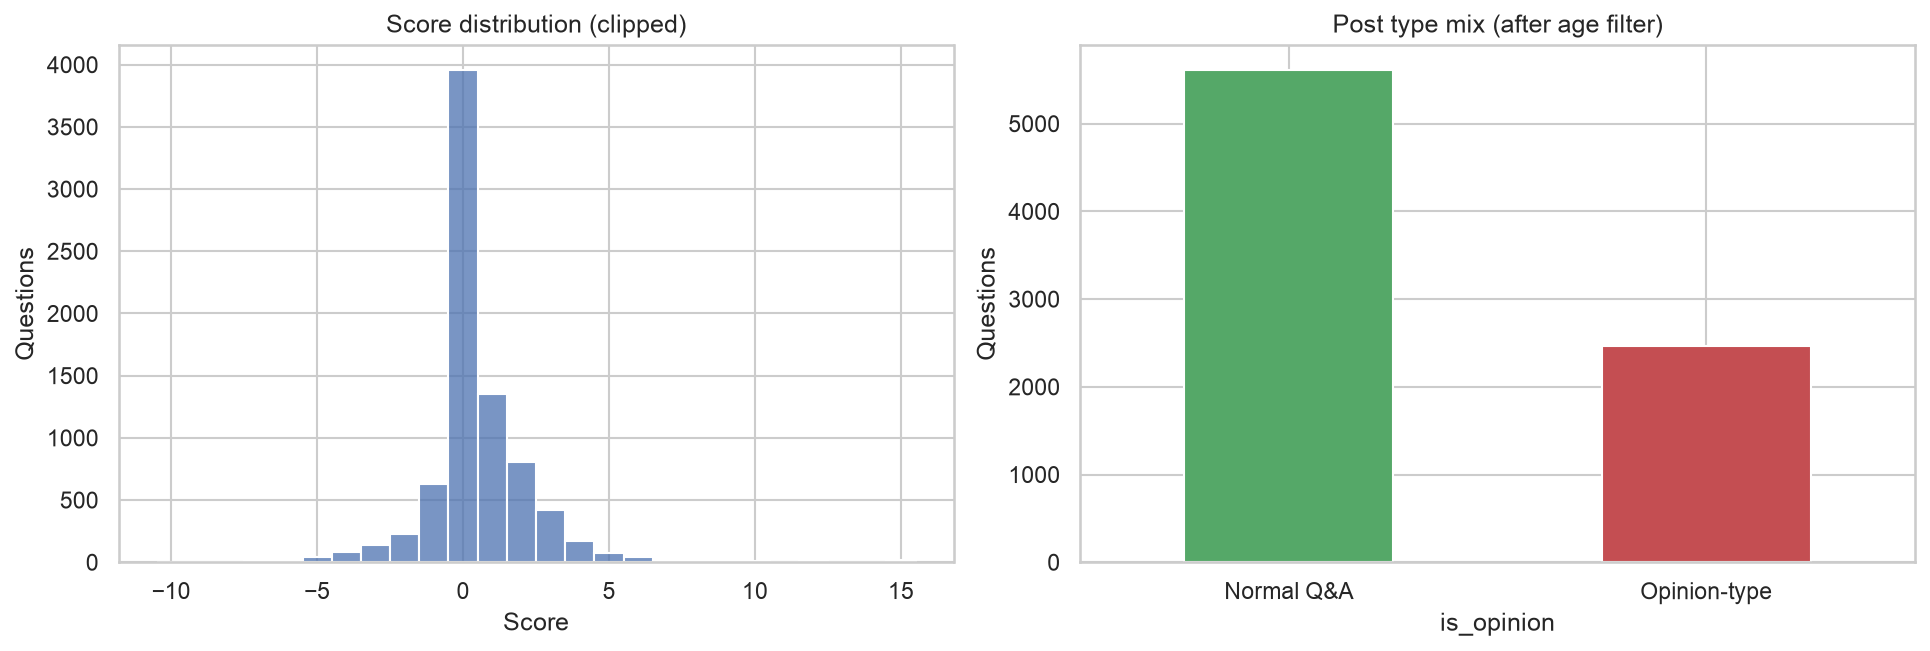

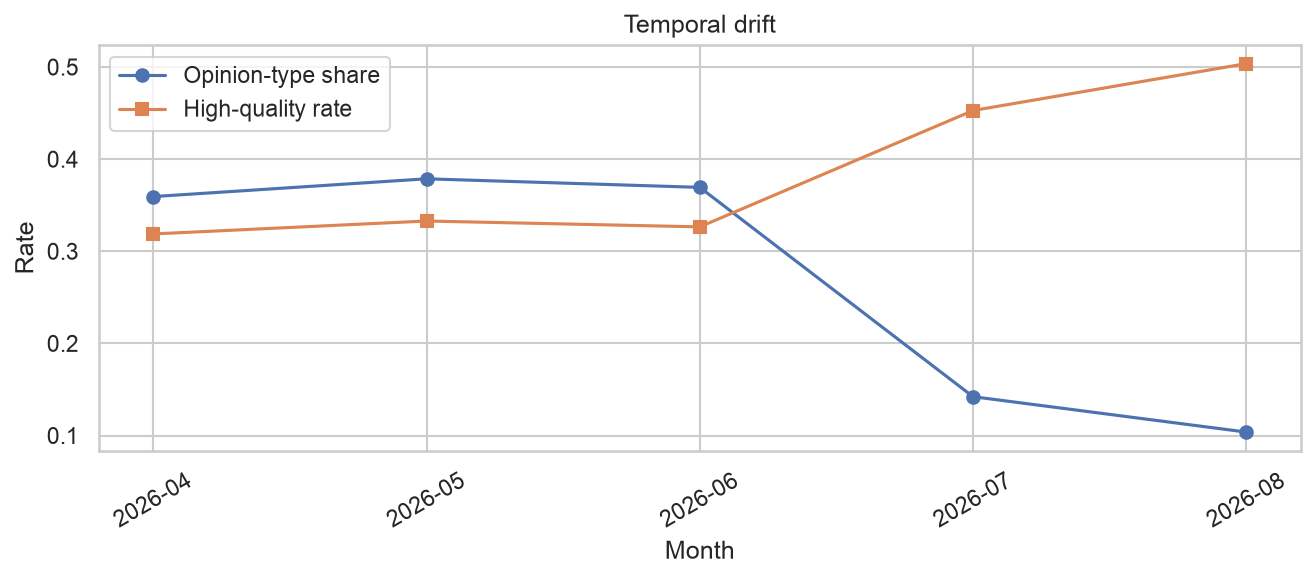

,month,n,opinion_rate,high_rate
0,2026-04,2268,0.359,0.319
1,2026-05,1986,0.379,0.333
2,2026-06,1703,0.369,0.326
3,2026-07,1175,0.142,0.453
4,2026-08,945,0.104,0.504


In [3]:
# 2. Load summary + confound tables
summary = json.loads((RES_DIR / "summary.json").read_text())
type_stats = pd.read_csv(RES_DIR / "post_type_stats.csv")
monthly = pd.read_csv(RES_DIR / "monthly_drift.csv")
display(Markdown(
    f"""**Snapshot date:** {summary['snapshot_date']}  ·  **Age filter:** ≥ {summary['min_age_days']} days  
**After filter:** {summary['n_after_age_filter']} questions  
**Normal Q&A:** {summary['n_normal']} (high-quality rate {summary['normal_high_rate']:.1%})  
**Opinion-type:** {summary['n_opinion']} (high-quality rate {summary['opinion_high_rate']:.1%})  
`FavoriteCount` is always 0 in this API export (not usable).
"""
))
display(type_stats)
display(Image(filename=str(FIG_DIR / "01_score_distribution.png")))
display(Image(filename=str(FIG_DIR / "02_temporal_drift.png")))
display(monthly.round(3))


## 3. Primary task definition

- **Population:** normal questions only (exclude opinion-type tags)
- **Label:** `Score >= 1` → high, `Score <= 0` → low  
  Limitation: Score 0 often means *unvoted*, not necessarily bad — see sensitivity analysis.
- **No leakage:** score, views, answers, comments, accepted-answer, reputation, ids/dates excluded from features
- **Features**
  - `text`: TF-IDF on title + body prose + **code text**
  - `struct`: lengths, code/links/lists/style (tags **not** included)
  - `tags`: binary tag indicators alone
  - `text+struct`: content quality signal without tags
  - `all`: text + struct + tags


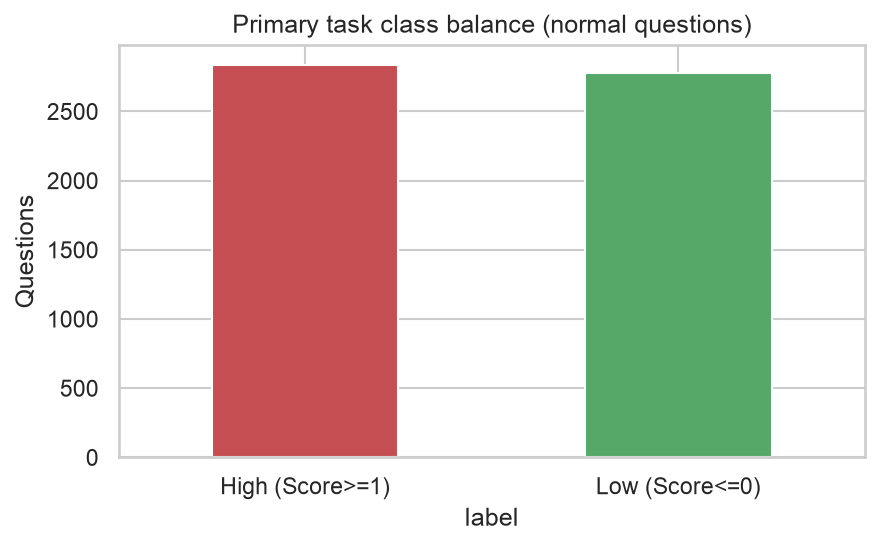

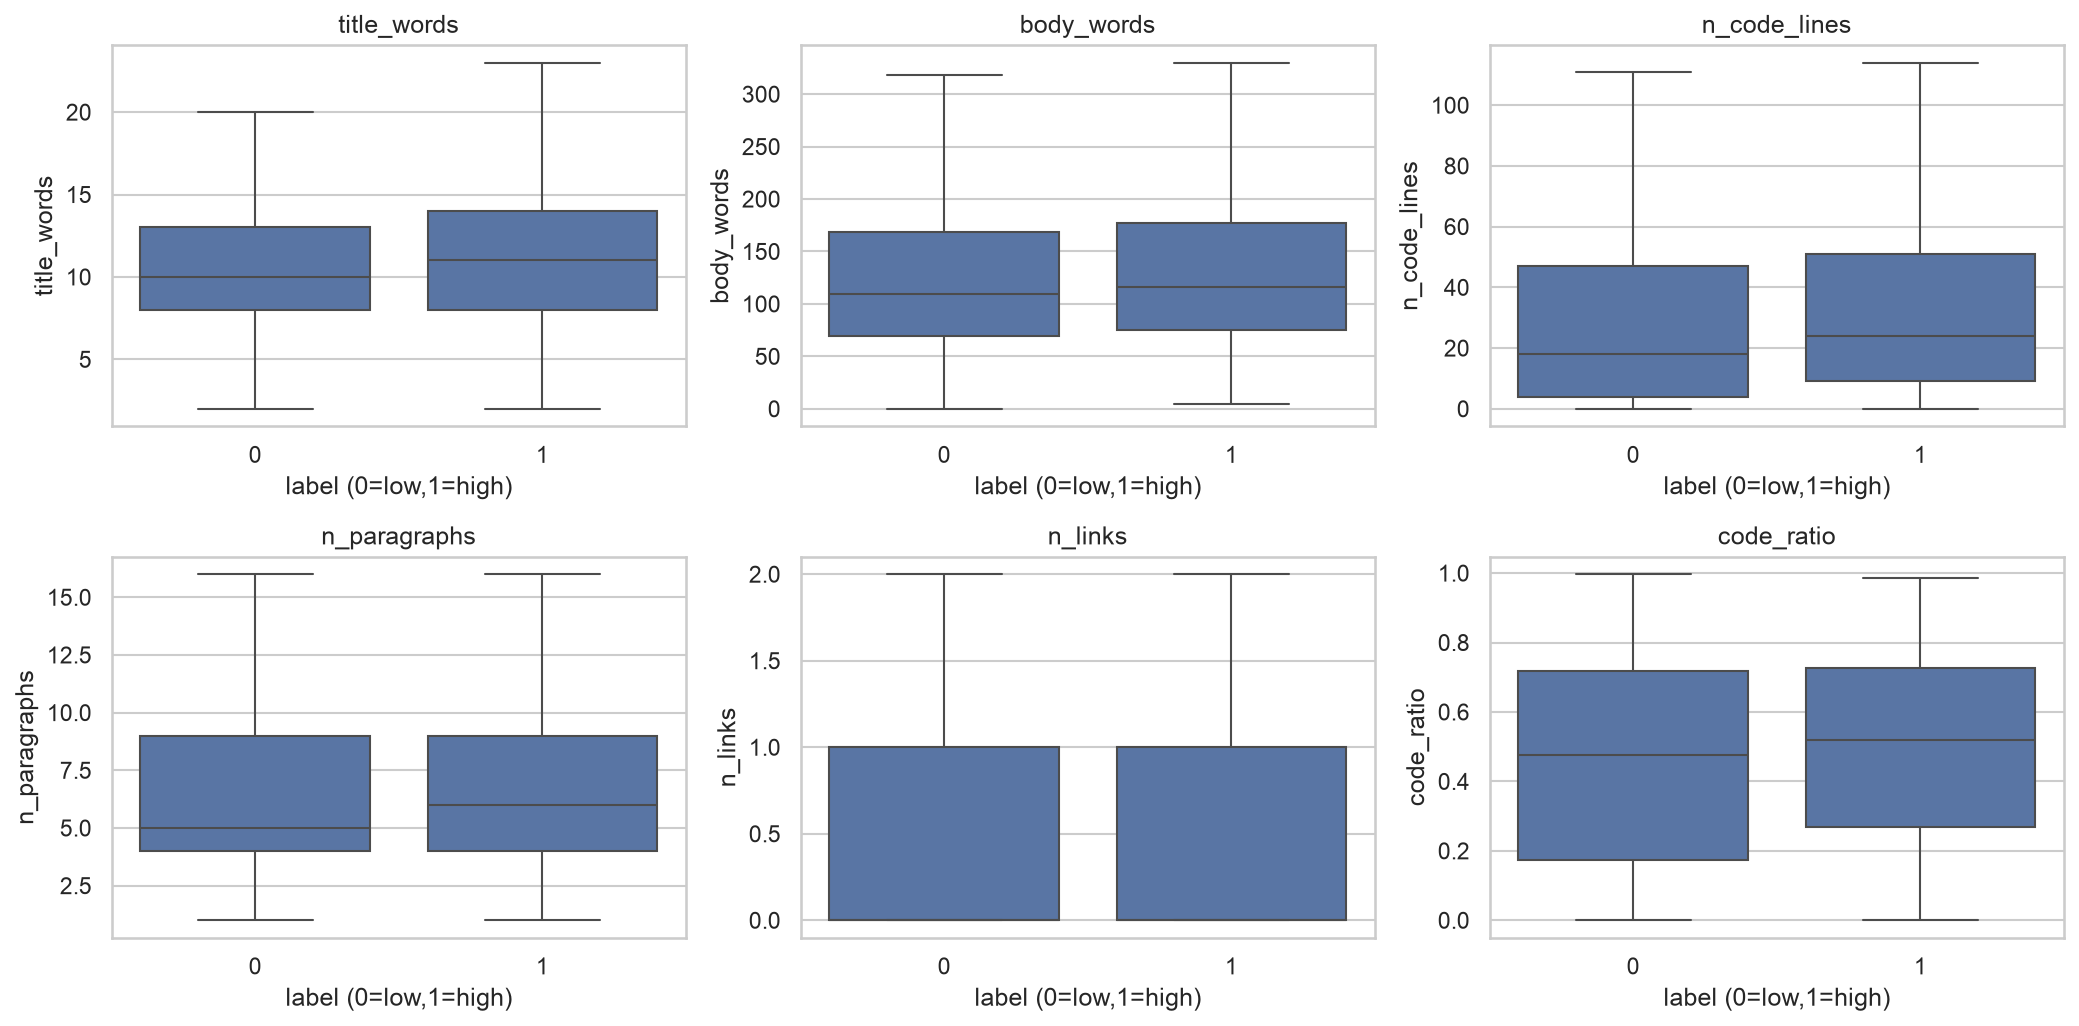

In [4]:
# 3. Primary class balance / structural EDA figures
display(Image(filename=str(FIG_DIR / "03_class_balance_normal.png")))
display(Image(filename=str(FIG_DIR / "04_structural_by_class.png")))


## 4. Primary results (normal questions, random stratified split)


CV-selected model: Logistic Regression | all
Held-out test: {'Accuracy': 0.642, 'Precision': 0.668, 'Recall': 0.581, 'F1': 0.621, 'Macro F1': 0.641, 'ROC-AUC': 0.694}
Baselines:


,Model,F1,ROC-AUC
0,Dummy (majority),0.671,0.500
1,Dummy (stratified),0.506,0.502
2,Dummy (all-high),0.671,0.500


Note: all-high/majority F1 looks strong because classes are ~balanced; AUC=0.5 shows they are uninformative.


### Cross-validation (selection criterion = ROC-AUC)

,Model,Features,CV ROC-AUC (mean),CV ROC-AUC (std),Best params
12,Logistic Regression,all,0.675,0.016,{'C': 0.5}
13,Naive Bayes,all,0.657,0.020,"{'alpha': 1.0, 'fit_prior': True}"
9,Logistic Regression,text+struct,0.649,0.022,{'C': 1.0}
14,Random Forest,all,0.649,0.012,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
6,Logistic Regression,tags,0.647,0.010,{'C': 5.0}
8,Random Forest,tags,0.646,0.011,"{'max_depth': 20, 'max_features': 'sqrt', 'min..."
10,Naive Bayes,text+struct,0.644,0.015,"{'alpha': 1.0, 'fit_prior': True}"
11,Random Forest,text+struct,0.640,0.011,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
0,Logistic Regression,text,0.639,0.016,{'C': 0.5}
1,Naive Bayes,text,0.638,0.017,"{'alpha': 1.0, 'fit_prior': True}"


### Held-out test

,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC
15,Logistic Regression,all,0.642,0.668,0.581,0.621,0.694
12,Logistic Regression,text+struct,0.625,0.635,0.606,0.620,0.671
16,Naive Bayes,all,0.620,0.614,0.667,0.640,0.669
17,Random Forest,all,0.615,0.633,0.567,0.598,0.667
9,Logistic Regression,tags,0.609,0.640,0.514,0.570,0.664
13,Naive Bayes,text+struct,0.609,0.596,0.701,0.644,0.660
4,Naive Bayes,text,0.618,0.628,0.599,0.613,0.653
3,Logistic Regression,text,0.607,0.620,0.572,0.595,0.649
11,Random Forest,tags,0.610,0.703,0.396,0.507,0.646
14,Random Forest,text+struct,0.596,0.610,0.555,0.581,0.646


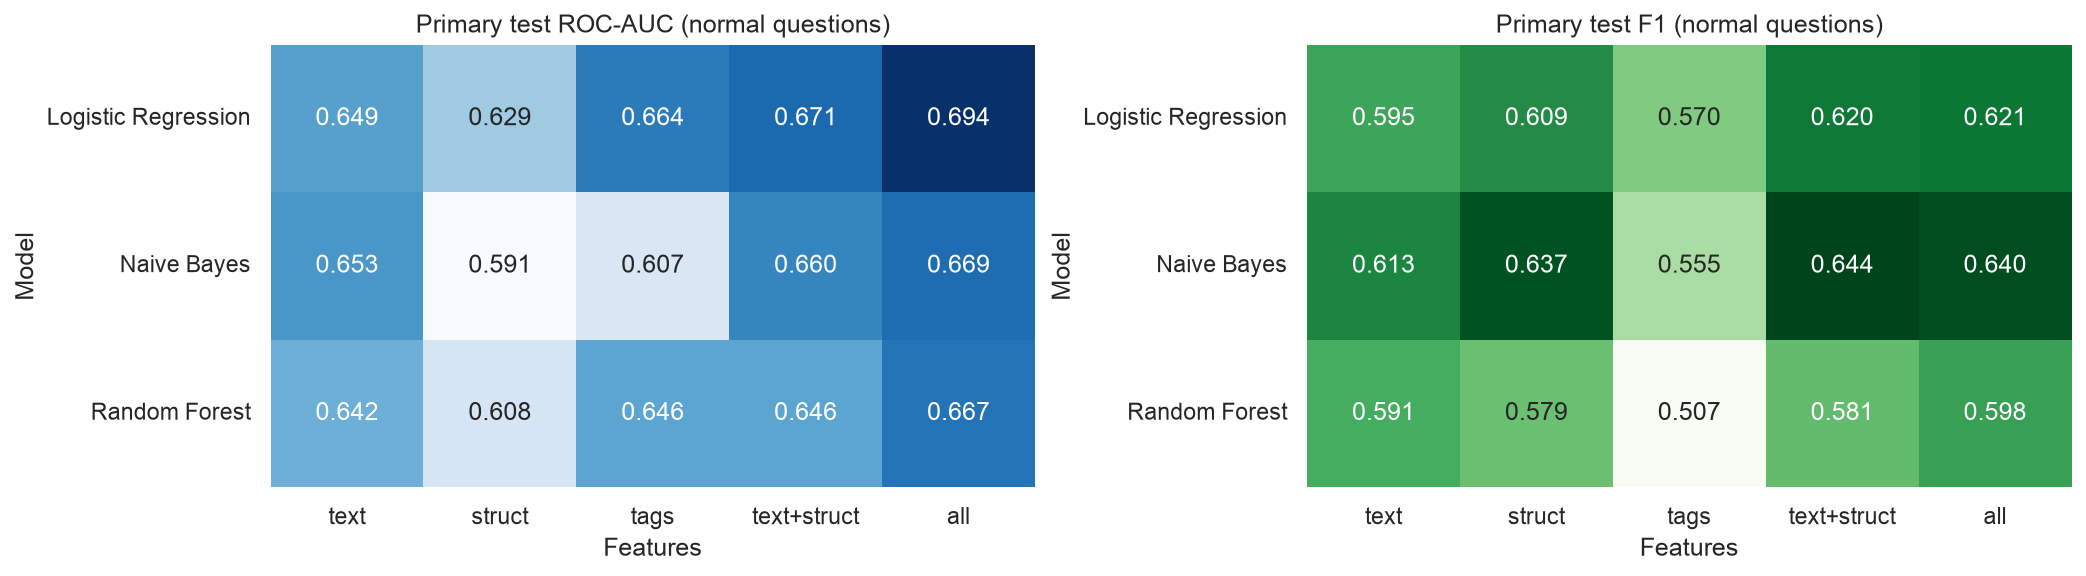

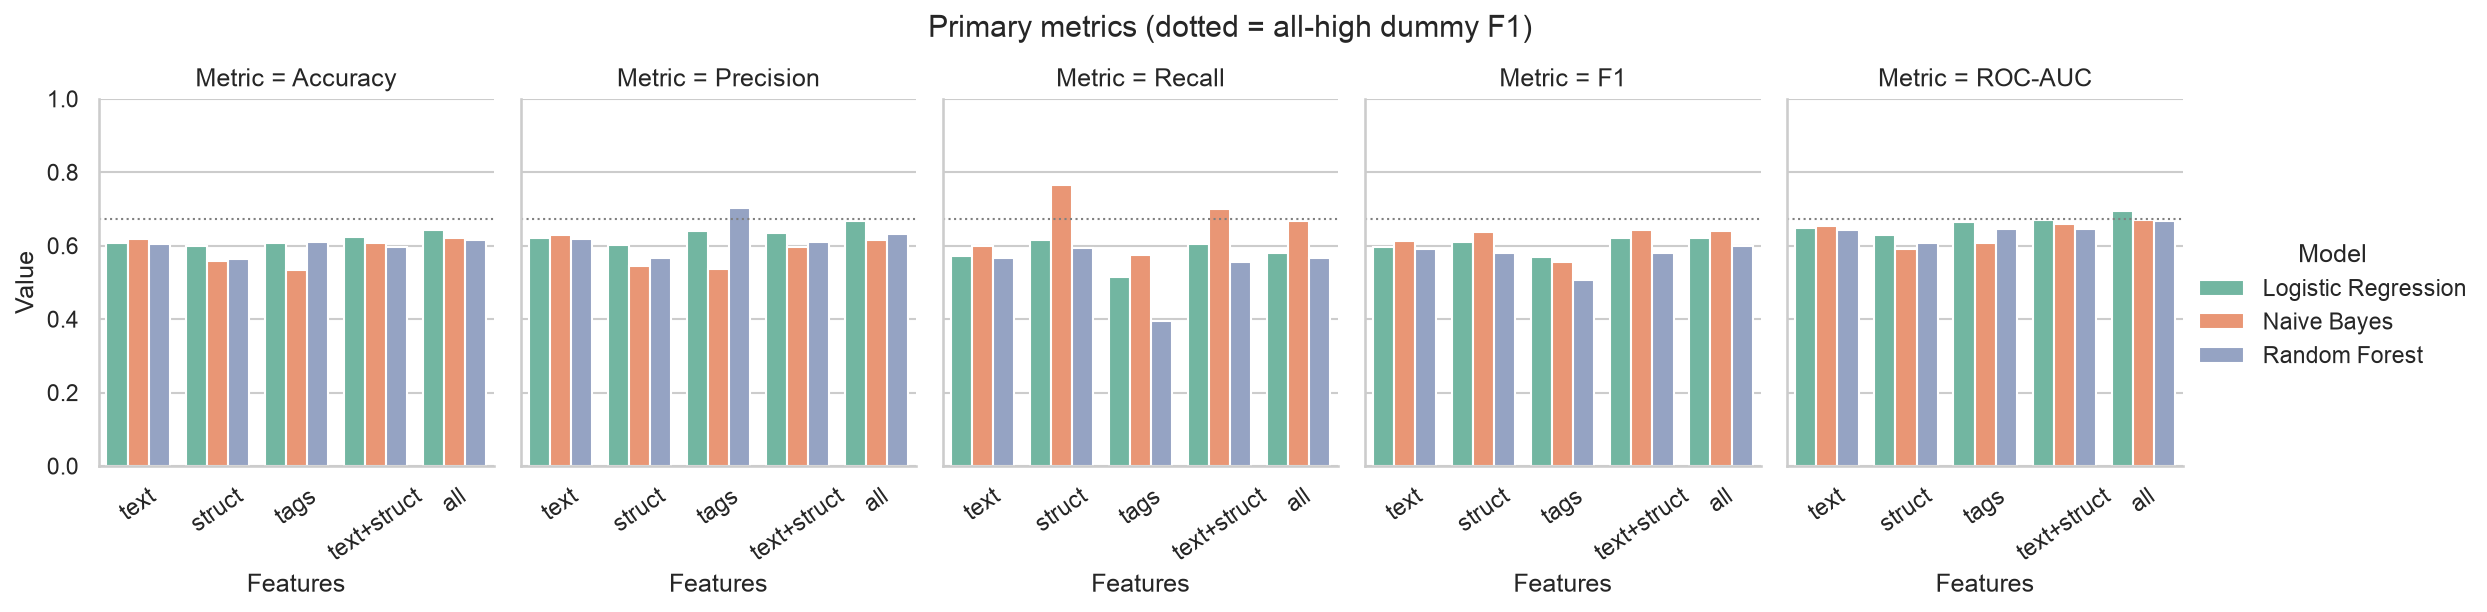

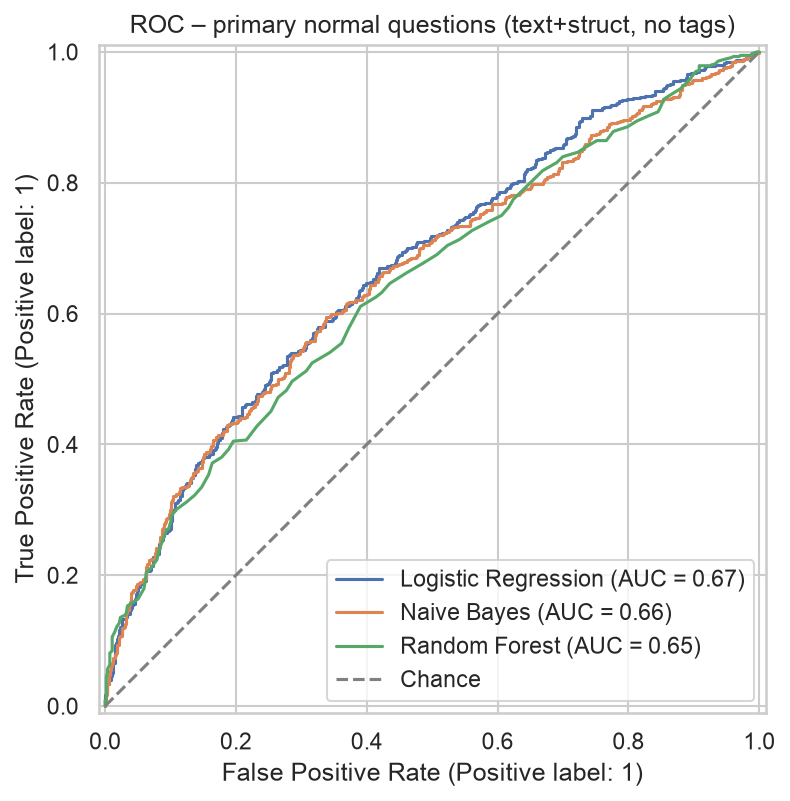

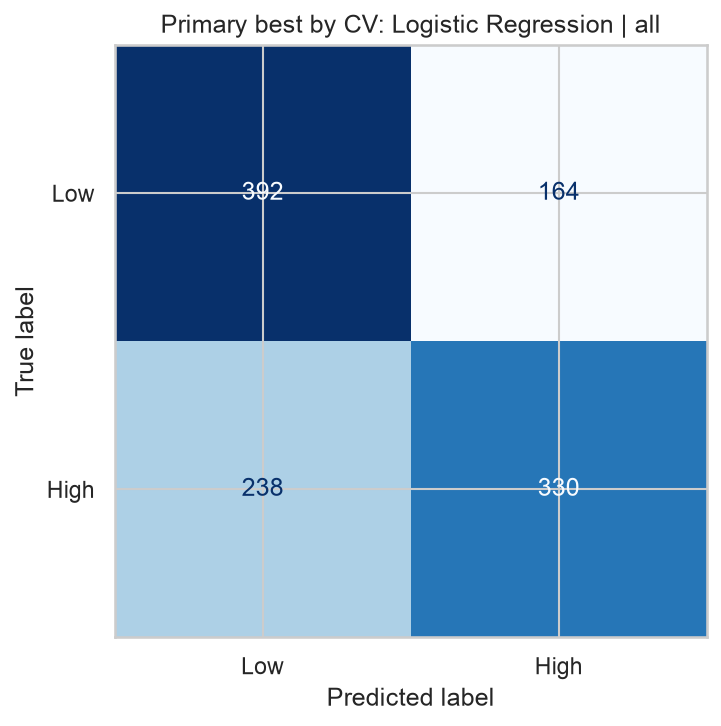

In [5]:
# 4. Primary metrics — headline is ROC-AUC
cv = pd.read_csv(RES_DIR / "cv_results.csv")
test = pd.read_csv(RES_DIR / "test_results.csv")
primary_cv = cv[cv.Suite == "primary_normal_random"].sort_values("CV ROC-AUC (mean)", ascending=False)
primary_test = test[test.Suite == "primary_normal_random"].sort_values("ROC-AUC", ascending=False)

best = summary["primary_best_by_cv"]
print(f"CV-selected model: {best['model']} | {best['features']}")
print("Held-out test:", {k: round(v, 3) for k, v in summary['primary_best_test'].items()})
print("Baselines:")
display(pd.DataFrame(summary["primary_baselines"]).round(3))
print("Note: all-high/majority F1 looks strong because classes are ~balanced; AUC=0.5 shows they are uninformative.")

display(Markdown("### Cross-validation (selection criterion = ROC-AUC)"))
display(primary_cv[["Model", "Features", "CV ROC-AUC (mean)", "CV ROC-AUC (std)", "Best params"]].round(3).head(15))
display(Markdown("### Held-out test"))
display(primary_test[["Model", "Features", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].round(3))

display(Image(filename=str(FIG_DIR / "07_featureset_heatmap_primary.png")))
display(Image(filename=str(FIG_DIR / "08_test_metrics_primary.png")))
display(Image(filename=str(FIG_DIR / "06_roc_primary_textstruct.png")))
display(Image(filename=str(FIG_DIR / "05_confusion_primary_best.png")))


### Reading the primary table
- **Recommended content-quality model:** Logistic Regression with `text+struct` (no tags) — AUC ≈ content/writing signal.
- **`all` (with tags)** can be slightly higher; topical tags still carry some signal even on normal questions, but they are *not* the same as writing quality.
- **`struct` alone** is weaker than text once opinion-types are removed — the old claim that “structural features dominate” was mostly **tags** bundled into “structural”.


,contrast,delta_AUC,AUC 95% CI,delta_F1,F1 95% CI
0,textstruct_minus_text,0.022,"[0.002, 0.043]",0.025,"[-0.003, 0.053]"
1,all_minus_textstruct,0.022,"[0.001, 0.043]",0.002,"[-0.027, 0.030]"
2,tags_minus_textstruct,-0.007,"[-0.046, 0.030]",-0.050,"[-0.092, -0.010]"


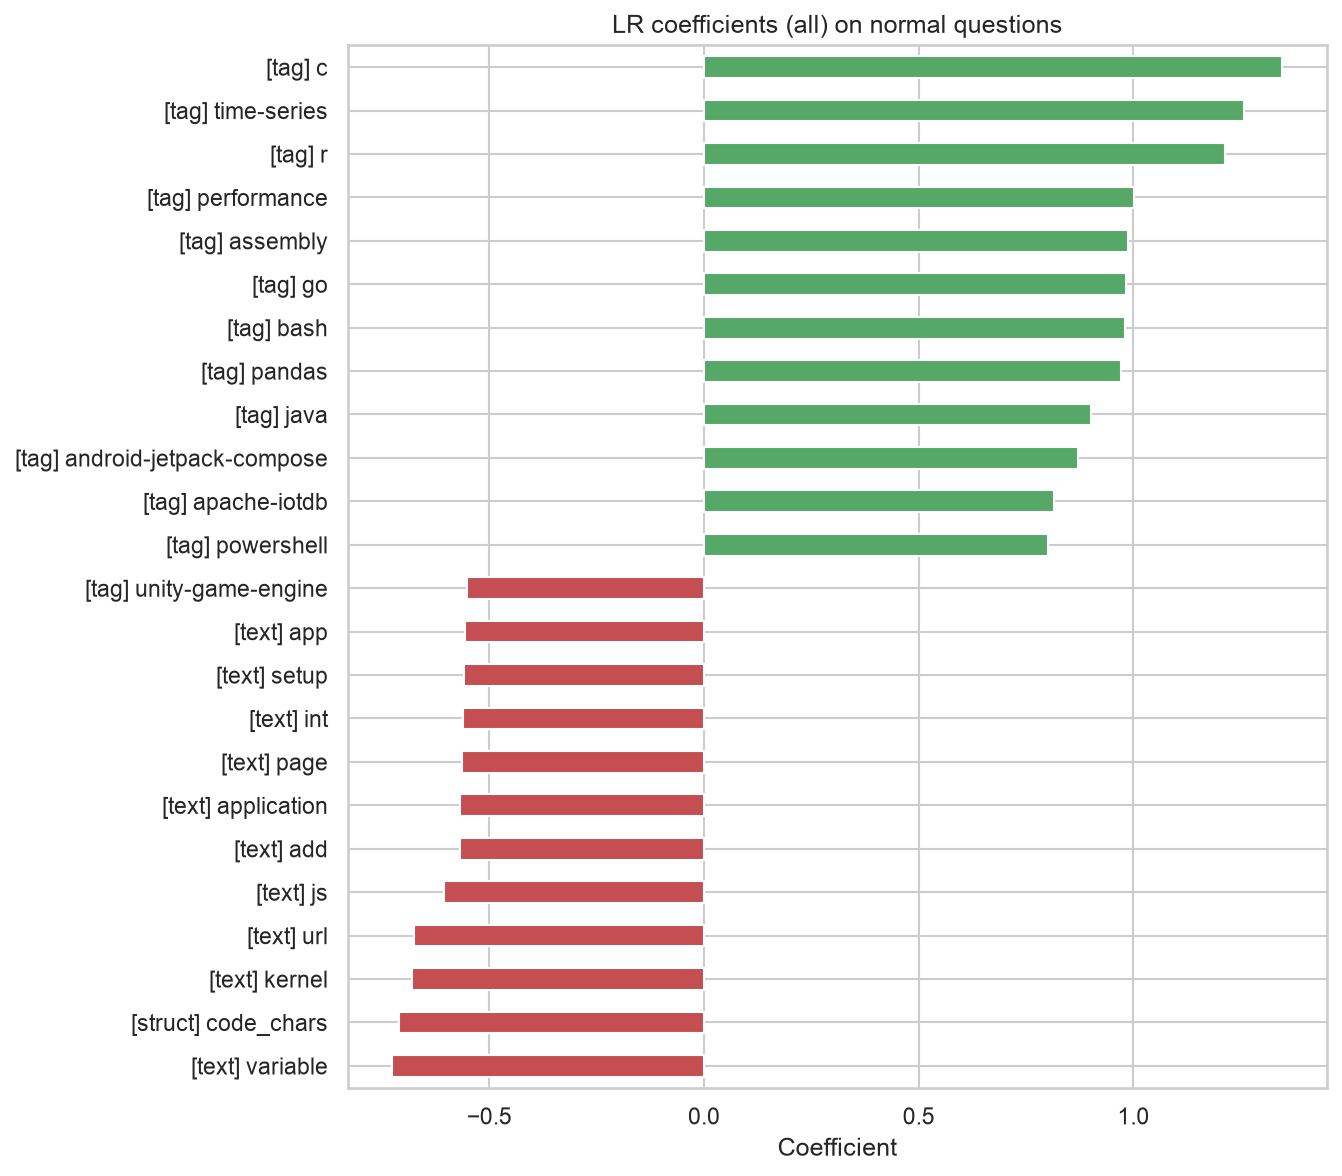

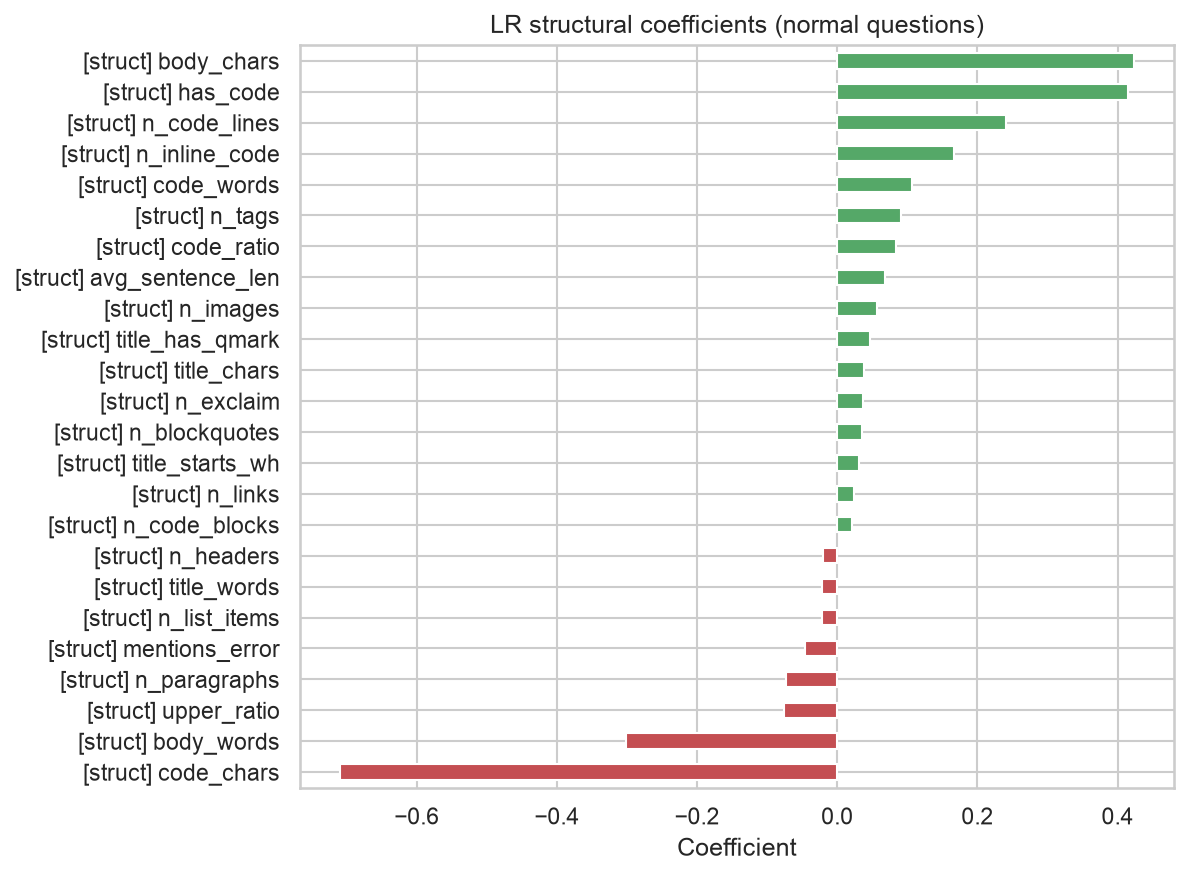

In [6]:
# 4b. Bootstrap deltas (LR)
boot = summary["bootstrap"]
rows = []
for k, v in boot.items():
    rows.append({
        "contrast": k,
        "delta_AUC": round(v["delta_auc_mean"], 3),
        "AUC 95% CI": f"[{v['delta_auc_ci95'][0]:.3f}, {v['delta_auc_ci95'][1]:.3f}]",
        "delta_F1": round(v["delta_f1_mean"], 3),
        "F1 95% CI": f"[{v['delta_f1_ci95'][0]:.3f}, {v['delta_f1_ci95'][1]:.3f}]",
    })
display(pd.DataFrame(rows))
display(Image(filename=str(FIG_DIR / "09_lr_coefficients_primary.png")))
display(Image(filename=str(FIG_DIR / "10_lr_structural_primary.png")))


## 5. Chronological robustness (normal questions)


CV-selected: {'model': 'Logistic Regression', 'features': 'all'}
Chrono held-out: {'Accuracy': 0.597, 'Precision': 0.61, 'Recall': 0.615, 'F1': 0.612, 'Macro F1': 0.596, 'ROC-AUC': 0.635}


,Model,Features,F1,ROC-AUC
30,Logistic Regression,text+struct,0.627,0.648
31,Naive Bayes,text+struct,0.642,0.641
32,Random Forest,text+struct,0.599,0.639
33,Logistic Regression,all,0.612,0.635
21,Logistic Regression,text,0.600,0.635
22,Naive Bayes,text,0.594,0.634
35,Random Forest,all,0.596,0.633
23,Random Forest,text,0.577,0.629
34,Naive Bayes,all,0.625,0.626
24,Logistic Regression,struct,0.610,0.605


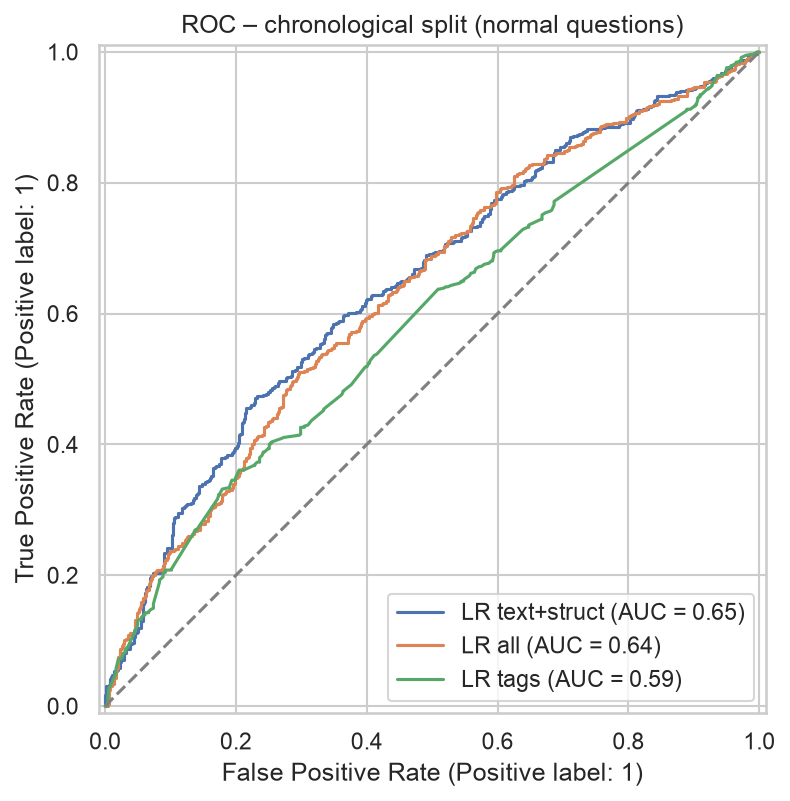

Random-split AUC falls under distribution shift — models are not fully time-stable.


In [7]:
# 5. Chronological split
chrono_test = test[test.Suite == "primary_normal_chrono"].sort_values("ROC-AUC", ascending=False)
print("CV-selected:", summary["chrono_best_by_cv"])
print("Chrono held-out:", {k: round(v, 3) for k, v in summary["chrono_best_test"].items()})
display(chrono_test[["Model", "Features", "F1", "ROC-AUC"]].round(3).head(12))
display(Image(filename=str(FIG_DIR / "11_roc_chrono.png")))
print("Random-split AUC falls under distribution shift — models are not fully time-stable.")


## 6. Secondary analysis: all posts (documents the tag confound)

When opinion-type posts are included, **tags alone** nearly match the full model. This is expected: those tags are almost deterministic predictors of low scores. This suite is reported for transparency, **not** as the primary quality result.


,Model,Features,F1,ROC-AUC
51,Logistic Regression,all,0.689,0.824
45,Logistic Regression,tags,0.676,0.806
47,Random Forest,tags,0.656,0.804
46,Naive Bayes,tags,0.655,0.795
52,Naive Bayes,all,0.485,0.790
53,Random Forest,all,0.619,0.765
48,Logistic Regression,text+struct,0.604,0.748
39,Logistic Regression,text,0.578,0.721
49,Naive Bayes,text+struct,0.499,0.719
50,Random Forest,text+struct,0.587,0.716


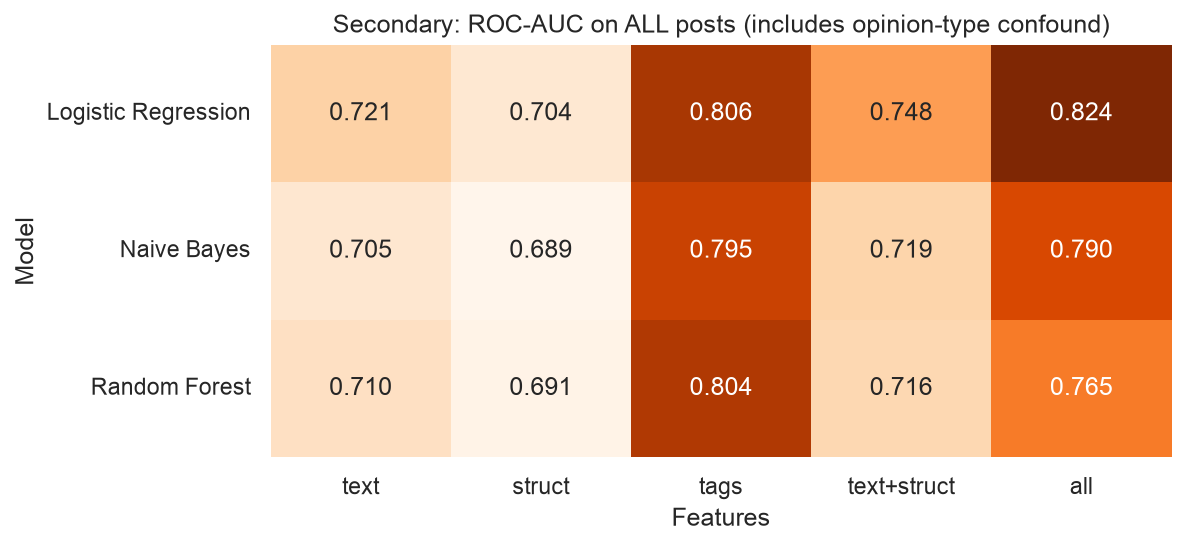

Secondary CV-selected: {'model': 'Logistic Regression', 'features': 'all'}
Secondary test: {'Accuracy': 0.73, 'Precision': 0.595, 'Recall': 0.817, 'F1': 0.689, 'Macro F1': 0.725, 'ROC-AUC': 0.824}


In [8]:
# 6. All-posts confound table
all_test = test[test.Suite == "secondary_all_posts"].sort_values("ROC-AUC", ascending=False)
display(all_test[["Model", "Features", "F1", "ROC-AUC"]].round(3))
display(Image(filename=str(FIG_DIR / "12_featureset_heatmap_allposts.png")))
print("Secondary CV-selected:", summary["secondary_all_best_by_cv"])
print("Secondary test:", {k: round(v, 3) for k, v in summary["secondary_all_best_test"].items()})


## 7. Sensitivity: drop Score == 0

Score 0 is ambiguous (often “no votes yet”). Here we keep only Score ≥ 1 vs Score ≤ −1 on normal questions.


In [9]:
# 7. Drop-zero sensitivity
sens = test[test.Suite == "sensitivity_drop_zero"].sort_values("ROC-AUC", ascending=False)
display(sens[["Model", "Features", "F1", "ROC-AUC"]].round(3))
print("CV-selected:", summary["sensitivity_drop_zero_best_by_cv"])
print("Test:", {k: round(v, 3) for k, v in summary["sensitivity_drop_zero_best_test"].items()})


,Model,Features,F1,ROC-AUC
66,Logistic Regression,all,0.810,0.726
67,Naive Bayes,all,0.881,0.724
63,Logistic Regression,text+struct,0.804,0.713
64,Naive Bayes,text+struct,0.879,0.700
68,Random Forest,all,0.885,0.699
65,Random Forest,text+struct,0.852,0.688
58,Naive Bayes,text,0.882,0.681
62,Random Forest,struct,0.871,0.667
57,Logistic Regression,text,0.806,0.665
60,Logistic Regression,struct,0.749,0.660


CV-selected: {'model': 'Logistic Regression', 'features': 'all'}
Test: {'Accuracy': 0.717, 'Precision': 0.861, 'Recall': 0.764, 'F1': 0.81, 'Macro F1': 0.629, 'ROC-AUC': 0.726}


## 8. Conclusions

1. **Primary finding:** On normal Stack Overflow questions, posting-time text + structure predict quality better than chance (**LR `text+struct` ROC-AUC ≈ 0.67**; with tags **≈ 0.69**).  
2. **Headline metric should be ROC-AUC**, not F1 vs a stratified dummy — an all-high classifier gets F1 ≈ 0.67 with AUC 0.5 when classes are balanced.  
3. **The earlier “structural dominates text” story was largely a tag/post-type effect.** With tags separated and opinion posts removed, text matters; pure structure is weaker.  
4. **All-posts models look stronger mainly because they detect opinion-type tags** (secondary AUC ≈ 0.82 with tags).  
5. **Temporal shift is real:** chronological evaluation drops AUC (≈ 0.64).  
6. **Labels are noisy** (Score 0, 60-day proxy for fetch time). Dropping zeros raises AUC into the low–mid 0.70s but changes the task.

### Outputs
- `figures/` — primary + secondary plots  
- `results/test_results.csv`, `cv_results.csv`, `summary.json`  
- `Final_Report.pdf`, `Presentation.pdf`
